# Frazer and Hendry Formalism
$$T_{11}(s) = \frac{\gamma_1 + \kappa_2(s) - \kappa_{2r}}{D(s)}, \quad T_{12}(s) = \frac{-\sqrt{\gamma_1 \gamma_2}}{D(s)}$$
where
$$D(s) = (\kappa_2(s) - \kappa_{2r})(\gamma_2 - i k_1(s)) - i \gamma_1 k_1(s)$$
using the AMP production vector:
$$\frac{\mathrm{d}N}{\mathrm{d}M} = N_a \cdot p_1(s) \cdot |F_1(s)|^2$$
where $p_1(s) = \mathrm{Re}[k_1(s)]$.

# For the case where all are stable

                  MINUIT Fit Parameter Table (Frazer-Hendry Stable Case)                  
Parameter    | Fitted Value |  Uncertainty
------------------------------------------------------------------------------------------
gamma1       |     -0.29843 |      0.05611
gamma2       |      3.04097 |      0.52999
kappa2r      |      0.20315 |      0.01967
alpha2       |     -0.07474 |      0.07057
Na           |    271.84483 |     58.65975
------------------------------------------------------------------------------------------
Total Chi^2       : 50.378
Degrees of Freedom: 52
Chi^2 / dof       : 0.969
S-Matrix Pole: W_pole = 3.874653 + i(-0.000299) GeV
Pole Mass   M_R   : 3874.653 MeV
Pole Width  Gamma : 0.598 MeV
------------------------------------------------------------------------------------------
Ch 1 Angle theta1 = -1.58° | k1 = 0.732572 + i(-0.020262) | Re*Im<0: True
Ch 2 Angle theta2 = 106.88° | k2 = -0.067102 + i(0.221182) | Re*Im<0: True
Identified Riemann Sheet    : Sheet II

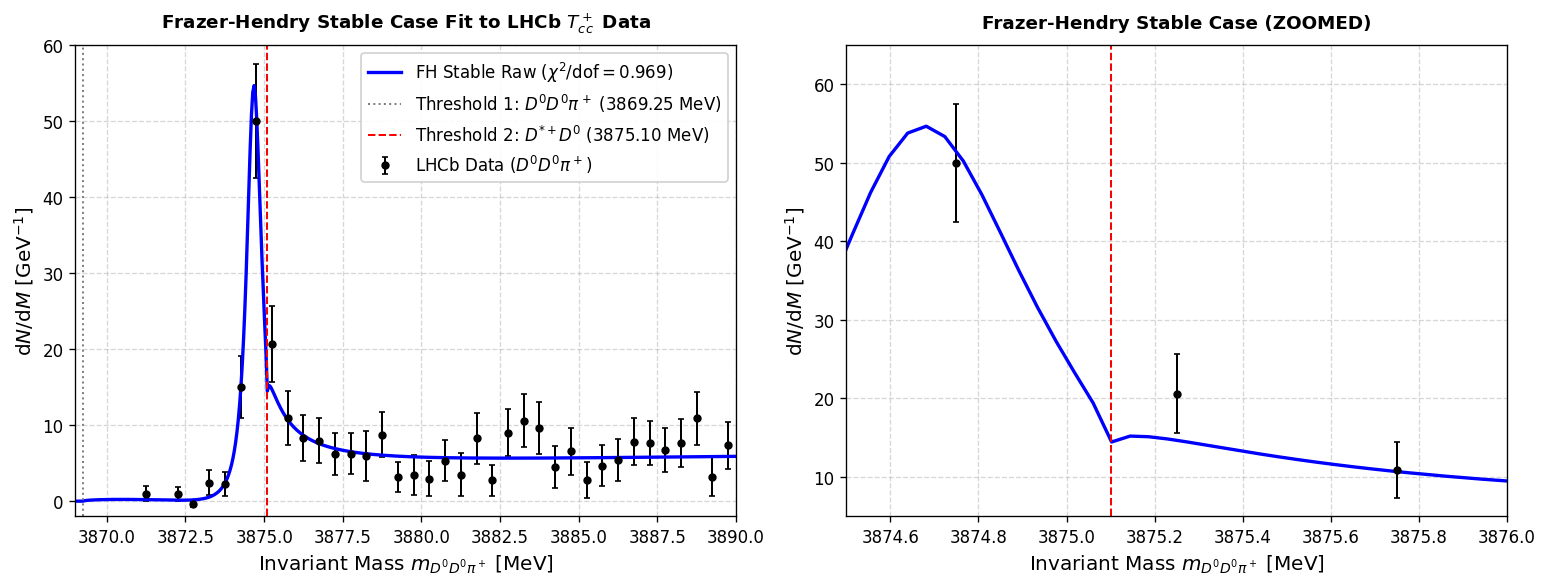

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from iminuit import Minuit
from iminuit.cost import LeastSquares

# Physical Constants & Thresholds
m_D0 = 1.86484     
m_Dstar = 2.01026  
m_pion = 0.13957   

M1, m1 = m_D0 + m_pion, m_D0  # Channel 1: (D0 pi+) + D0 (3.86925 GeV)
M2, m2 = m_Dstar, m_D0        # Channel 2: D*+ + D0       (3.87510 GeV) - Stable

p_unit = m_pion  # Momentum normalization scale (m_pion)

# Right-Hand Cut Square Root & Kinematics
def sqrt_rhc(z):
    """Complex square root with Right-Hand Cut along [0, +inf)."""
    z_c = np.asarray(z, dtype=np.complex128)
    r = np.abs(z_c)
    theta = np.angle(z_c)
    theta = np.where(theta < 0, theta + 2.0 * np.pi, theta)
    res = np.sqrt(r) * np.exp(1j * theta / 2.0)
    return res if isinstance(z, np.ndarray) else res.item()

def k_cm(s, M, m, sheet_sign=+1):
    """Center-of-mass momentum k(s) using Right-Hand Cut square root."""
    s_c = s + 1e-12j
    W = np.sqrt(s_c)
    sth = (M + m)**2
    sdiff = (M - m)**2
    z_th = s_c - sth
    z_diff = s_c - sdiff
    return sheet_sign * (sqrt_rhc(z_th) * np.sqrt(z_diff)) / (2.0 * W)

def fh_denom_general(W_complex, gamma1, gamma2, kappa2r, s1=+1, s2=+1):
    s = W_complex**2
    k1 = k_cm(s, M1, m1, sheet_sign=s1) / p_unit
    k2 = k_cm(s, M2, m2, sheet_sign=s2) / p_unit
    kappa2 = -1j * k2
    return (kappa2 - kappa2r) * (gamma2 - 1j * k1) - 1j * gamma1 * k1

def model_yield(E_MeV, gamma1, gamma2, kappa2r, alpha2, Na):
    """Raw Frazer-Hendry Model"""
    E_GeV = E_MeV / 1000.0
    s = E_GeV**2
    k1 = k_cm(s, M1, m1, sheet_sign=+1) / p_unit
    k2 = k_cm(s, M2, m2, sheet_sign=+1) / p_unit
    kappa2 = -1j * k2
    
    D = (kappa2 - kappa2r) * (gamma2 - 1j * k1) - 1j * gamma1 * k1
    T11 = (gamma1 + kappa2 - kappa2r) / D
    T12 = -np.sqrt(np.complex128(gamma1 * gamma2)) / D
    
    F1 = T11 + alpha2 * T12
    p1 = np.real(k1) * p_unit
    return Na * p1 * np.abs(F1)**2

# Load Dataset
data_path = r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv"
df_data = pd.read_csv(data_path, comment='#')
data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
data_yield = df_data.iloc[:, 3].values
data_err = df_data.iloc[:, 4].values

# MINUIT Optimization 
init_params = dict(gamma1=-0.3, gamma2=3.0, kappa2r=0.2, alpha2=-0.07, Na=270.0)
cost = LeastSquares(data_mass_MeV, data_yield, data_err, model_yield)
m = Minuit(cost, **init_params)

m.limits["gamma1"] = (-5.0, 5.0)
m.limits["gamma2"] = (-5.0, 5.0)
m.limits["kappa2r"] = (0.001, 3.0)
m.limits["alpha2"] = (-2.0, 2.0)
m.limits["Na"] = (1.0, 5000.0)

m.errors["gamma1"] = 0.05
m.errors["gamma2"] = 0.03
m.errors["kappa2r"] = 0.10
m.errors["alpha2"] = 0.01
m.errors["Na"] = 20.0

m.simplex()  # Pre-minimization
m.migrad()   # Main minimization
m.hesse()    # Uncertainty estimation
    
p_opt = {k: m.values[k] for k in init_params.keys()}
p_err = {k: m.errors[k] for k in init_params.keys()}
chi2 = m.fval
dof = len(data_yield) - m.nfit
chi2_dof = chi2 / dof

# Pole Search & Polar Riemann Sheet Identification
def find_and_identify_pole_polar(gamma1, gamma2, kappa2r):
    # Newton-Raphson solver for denominator root
    def denom_fn(W):
        return fh_denom_general(W, gamma1, gamma2, kappa2r, s1=+1, s2=+1)
    
    W = 3.8746 - 0.0003j
    h = 1e-7
    for _ in range(100):
        f = denom_fn(W)
        if abs(f) < 1e-12:
            break
        df = (denom_fn(W + h) - denom_fn(W - h)) / (2 * h)
        if abs(df) < 1e-15:
            break
        W -= f / df

    res = abs(denom_fn(W))
    if res >= 1e-8 or W.imag > 1e-5 or W.real <= 3.86:
        return None

    M_R = W.real * 1000.0
    Gamma_R = -2.0 * W.imag * 1000.0
    s_pole = W**2

    # Channel 1 Thresholds
    sth1 = (M1 + m1)**2
    sdiff1 = (M1 - m1)**2
    z_th1 = s_pole - sth1
    z_diff1 = s_pole - sdiff1

    # Channel 2 Thresholds
    sth2 = (M2 + m2)**2
    sdiff2 = (M2 - m2)**2
    z_th2 = s_pole - sth2
    z_diff2 = s_pole - sdiff2

    # Polar Representation: k = |k| * exp(i * theta)
    # 2*theta_1 in (-pi, 0) for open channel unphysical continuation
    two_theta1 = np.angle(z_th1)
    theta1 = two_theta1 / 2.0
    mag_k1 = (np.sqrt(np.abs(z_th1) * np.abs(z_diff1)) / (2.0 * np.abs(W))) / p_unit
    k1_p = mag_k1 * np.exp(1j * theta1)

    # 2*theta_2 in [0, 2*pi) for closed channel physical continuation
    two_theta2 = np.angle(z_th2) % (2.0 * np.pi)
    theta2 = two_theta2 / 2.0
    mag_k2 = (np.sqrt(np.abs(z_th2) * np.abs(z_diff2)) / (2.0 * np.abs(W))) / p_unit
    k2_p = mag_k2 * np.exp(1j * theta2)

    # Verify k_real * k_imag < 0
    k1_valid = (k1_p.real * k1_p.imag) < 0
    k2_valid = (k2_p.real * k2_p.imag) < 0

    s1_str = '+' if k1_p.imag >= 0 else '-'
    s2_str = '+' if k2_p.imag >= 0 else '-'

    sheet_map = {
        ('+', '+'): "Sheet I [tt]",
        ('-', '+'): "Sheet II [bt]",
        ('-', '-'): "Sheet III [bb]",
        ('+', '-'): "Sheet IV [tb]"
    }

    return W, M_R, Gamma_R, k1_p, k2_p, theta1, theta2, s1_str, s2_str, sheet_map[(s1_str, s2_str)], k1_valid, k2_valid

pole_res = find_and_identify_pole_polar(p_opt['gamma1'], p_opt['gamma2'], p_opt['kappa2r'])

# Summary Output
param_names = ["gamma1", "gamma2", "kappa2r", "alpha2", "Na"]

print("=" * 90)
print(f"{'MINUIT Fit Parameter Table (Frazer-Hendry Stable Case)':^90}")
print("=" * 90)
print(f"{'Parameter':<12} | {'Fitted Value':>12} | {'Uncertainty':>12}")
print("-" * 90)
for name in param_names:
    val = p_opt[name]
    err = p_err[name]
    print(f"{name:<12} | {val:12.5f} | {err:12.5f}")
print("-" * 90)
print(f"Total Chi^2       : {chi2:.3f}")
print(f"Degrees of Freedom: {dof}")
print(f"Chi^2 / dof       : {chi2_dof:.3f}")
print("=" * 90)

if pole_res:
    W_p, M_R, Gamma_R, k1_p, k2_p, th1, th2, s1_tag, s2_tag, sheet_str, k1_v, k2_v = pole_res
    print(f"S-Matrix Pole: W_pole = {W_p.real:.6f} + i({W_p.imag:.6f}) GeV")
    print(f"Pole Mass   M_R   : {M_R:.3f} MeV")
    print(f"Pole Width  Gamma : {Gamma_R:.3f} MeV")
    print("-" * 90)
    print(f"Ch 1 Angle theta1 = {np.degrees(th1):.2f}° | k1 = {k1_p.real:.6f} + i({k1_p.imag:.6f}) | Re*Im<0: {k1_v}")
    print(f"Ch 2 Angle theta2 = {np.degrees(th2):.2f}° | k2 = {k2_p.real:.6f} + i({k2_p.imag:.6f}) | Re*Im<0: {k2_v}")
    print(f"Identified Riemann Sheet    : {sheet_str}")
print("=" * 90)

# Plot Fit Spectrum (Raw Yield)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
m_th1 = (M1 + m1) * 1000.0
m_th2 = (M2 + m2) * 1000.0

E_fine_MeV = np.linspace(3869.0, 3890.0, 500)
yield_fit_fine = model_yield(
    E_fine_MeV,
    p_opt['gamma1'], p_opt['gamma2'], p_opt['kappa2r'],
    p_opt['alpha2'], p_opt['Na']
)
ax[0].errorbar(
    data_mass_MeV, data_yield, yerr=data_err,
    fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2,
    markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)'
)
ax[0].plot(E_fine_MeV, yield_fit_fine, color='blue', lw=2, label=r'FH Stable Raw ($\chi^2/\mathrm{dof} = ' + f'{chi2_dof:.3f}' + r'$)')
ax[0].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=r'Threshold 1: $D^0 D^0 \pi^+$ (' + f'{m_th1:.2f}' + r' MeV)')
ax[0].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=r'Threshold 2: $D^{*+} D^0$ (' + f'{m_th2:.2f}' + r' MeV)')
ax[0].set_title(r'Frazer-Hendry Stable Case Fit to LHCb $T_{cc}^+$ Data', fontsize=11, fontweight='bold', pad=10)
ax[0].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[0].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[0].set_xlim(3869, 3890)
ax[0].set_ylim(-2, 60)
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)

E_fine_MeV_ZOOM = np.linspace(3874.0, 3876.0, 20000)
yield_fit_fine_zoom = model_yield(
    E_fine_MeV_ZOOM,
    p_opt['gamma1'], p_opt['gamma2'], p_opt['kappa2r'],
    p_opt['alpha2'], p_opt['Na']
)
ax[1].errorbar(
    data_mass_MeV, data_yield, yerr=data_err,
    fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2,
    markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)'
)
ax[1].plot(E_fine_MeV, yield_fit_fine, color='blue', lw=2, label=r'FH Stable Raw ($\chi^2/\mathrm{dof} = ' + f'{chi2_dof:.3f}' + r'$)')
ax[1].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=r'Threshold 1: $D^0 D^0 \pi^+$ (' + f'{m_th1:.2f}' + r' MeV)')
ax[1].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=r'Threshold 2: $D^{*+} D^0$ (' + f'{m_th2:.2f}' + r' MeV)')
ax[1].set_title(r'Frazer-Hendry Stable Case (ZOOMED)', fontsize=11, fontweight='bold', pad=10)
ax[1].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[1].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[1].set_xlim(3874.5, 3876.0)
ax[1].set_ylim(5, 65)
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# For the Unstable Case
For the unstable Channel 2 case, the finite decay width of the $D^{*+}$ meson ($\Gamma_{D^{*+}} \approx 83.4\text{ keV}$, corresponding to $D^{*+} \to D^0 \pi^+$) is incorporated into the Frazer-Hendry scattering matrix by assigning a complex mass to the Channel 2 particle: $m_2 \to m_{D^{*+}} - i {\Gamma_{D^{*+}}}/{2}$. Consequently, 
$$k_2^2 \longrightarrow k_2^2 + i\delta$$
where
$$\left(2\frac{M_2m_2}{M_2 + m_2}\right) \left(\frac{\Gamma}{2}\right)$$

  MINUIT Fit Parameter Table (Frazer-Hendry Unstable Case, Raw Yield)   
Parameter    | Fitted Value |  Uncertainty
------------------------------------------------------------------------
gamma1       |     -0.27573 |      0.05191
gamma2       |      2.32605 |      0.36756
kappa2r      |      0.20646 |      0.01643
alpha2       |     -0.08641 |      0.07527
Na           |    177.11384 |     30.01206
------------------------------------------------------------------------
Total Chi^2       : 50.818
Degrees of Freedom: 52
Chi^2 / dof       : 0.977
S-Matrix Pole: W_pole = 3.874609 + i(-0.000446) GeV
Pole Mass   M_R   : 3874.609 MeV
Pole Width  Gamma : 0.891 MeV
------------------------------------------------------------------------
Ch 1 Angle theta1 = -2.38° | k1 = 0.729948 + i(-0.030324) | Re*Im<0: True
Ch 2 Angle theta2 = 108.21° | k2 = -0.076933 + i(0.233843) | Re*Im<0: True
Identified Riemann Sheet    : Sheet II [bt]


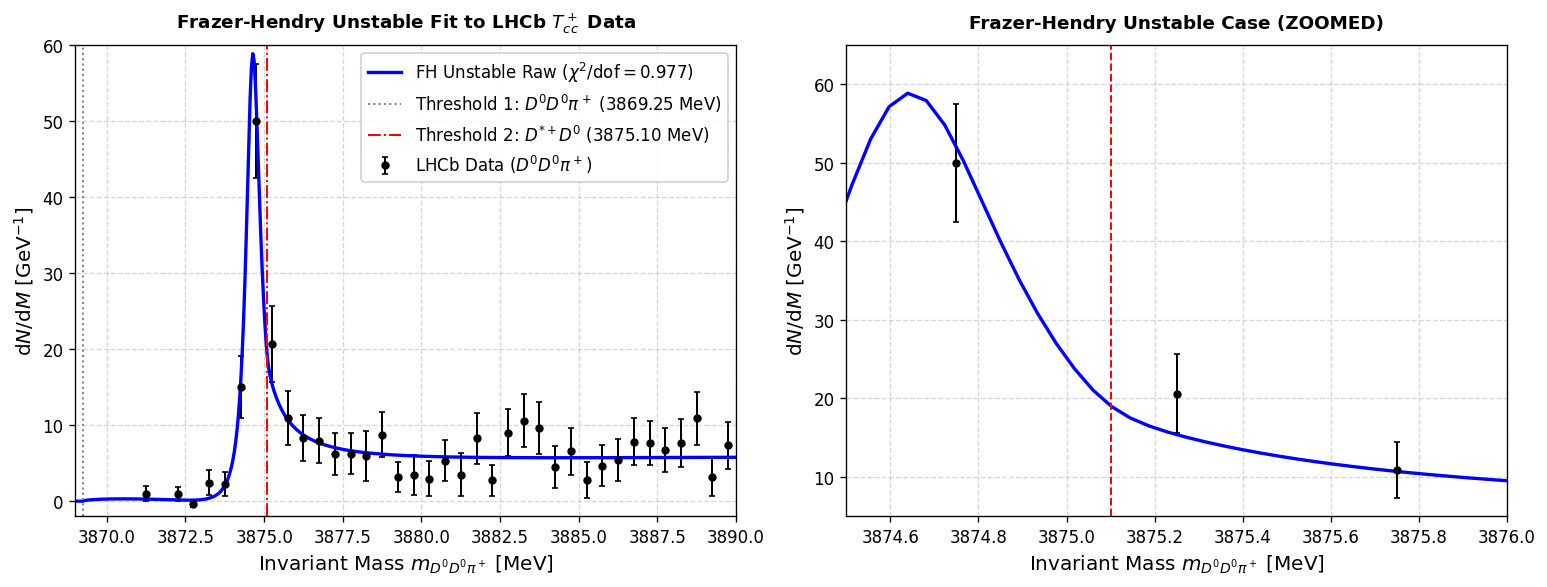

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from iminuit import Minuit
from iminuit.cost import LeastSquares

# Physical Constants & Thresholds
m_D0 = 1.86484     
m_Dstar = 2.01026  
m_pion = 0.13957   
Gamma_Dstar = 83.4e-6  # 83.4 keV in GeV

M1, m1 = m_D0 + m_pion, m_D0  # Channel 1: (D0 pi+) + D0
M2, m2 = m_Dstar, m_D0        # Channel 2: D*+ + D0

p_unit = m_pion  # Momentum normalization scale (m_pion)

# Kinematics with RHC & Unstable D*+
def sqrt_rhc(z):
    """Complex square root with Right-Hand Cut along [0, +inf)."""
    z_c = np.asarray(z, dtype=np.complex128)
    r = np.abs(z_c)
    theta = np.angle(z_c)
    theta = np.where(theta < 0, theta + 2.0 * np.pi, theta)
    res = np.sqrt(r) * np.exp(1j * theta / 2.0)
    return res if isinstance(z, np.ndarray) else res.item()

def k1_func(s, sheet_sign=+1):
    s_c = s + 1e-12j
    W = np.sqrt(s_c)
    sth = (M1 + m1)**2
    sdiff = (M1 - m1)**2
    z_th = s_c - sth
    z_diff = s_c - sdiff
    return sheet_sign * (sqrt_rhc(z_th) * np.sqrt(z_diff)) / (2.0 * W)

def k2_func_unstable(s, width=Gamma_Dstar, sheet_sign=+1):
    """Channel 2 momentum for UNSTABLE D*+ (complex mass m2_comp = m2 - i * width / 2)."""
    s_c = s + 1e-12j
    W = np.sqrt(s_c)
    m2_comp = m2 - 1j * (width / 2.0)
    s_th = (M2 + m2_comp)**2
    k2_sq = (s_c - s_th) * (s_c - (M2 - m2_comp)**2) / ((2.0 * W)**2)
    delta = (2.0 * M2 * m2 / (M2 + m2)) * (width / 2.0)
    return sheet_sign * sqrt_rhc(k2_sq + 1j * delta)

def fh_denom_general(W_complex, gamma1, gamma2, kappa2r, s1=+1, s2=+1):
    s = W_complex**2
    k1 = k1_func(s, sheet_sign=s1) / p_unit
    k2 = k2_func_unstable(s, width=Gamma_Dstar, sheet_sign=s2) / p_unit
    kappa2 = -1j * k2
    return (kappa2 - kappa2r) * (gamma2 - 1j * k1) - 1j * gamma1 * k1

def model_yield(E_MeV, gamma1, gamma2, kappa2r, alpha2, Na):
    E_GeV = E_MeV / 1000.0
    s = E_GeV**2
    k1 = k1_func(s, sheet_sign=+1) / p_unit
    k2 = k2_func_unstable(s, width=Gamma_Dstar, sheet_sign=+1) / p_unit
    kappa2 = -1j * k2
    
    D = (kappa2 - kappa2r) * (gamma2 - 1j * k1) - 1j * gamma1 * k1
    T11 = (gamma1 + kappa2 - kappa2r) / D
    T12 = -np.sqrt(np.complex128(gamma1 * gamma2)) / D
    
    F1 = T11 + alpha2 * T12
    p1 = np.real(k1) * p_unit
    return Na * p1 * np.abs(F1)**2

# Load Dataset
data_path = r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv"
df_data = pd.read_csv(data_path, comment='#')
data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
data_yield = df_data.iloc[:, 3].values
data_err = df_data.iloc[:, 4].values

# MINUIT Optimization Process
init_params = dict(gamma1=-0.286, gamma2=2.646, kappa2r=0.205, alpha2=-0.081, Na=216.55)
cost = LeastSquares(data_mass_MeV, data_yield, data_err, model_yield)
m = Minuit(cost, **init_params)

# Set physical limits
m.limits["gamma1"] = (-5.0, 5.0)
m.limits["gamma2"] = (-5.0, 5.0)
m.limits["kappa2r"] = (0.001, 3.0)
m.limits["alpha2"] = (-2.0, 2.0)
m.limits["Na"] = (1.0, 5000.0)

# Set initial step sizes
m.errors["gamma1"] = 0.05
m.errors["gamma2"] = 0.03
m.errors["kappa2r"] = 0.10
m.errors["alpha2"] = 0.01
m.errors["Na"] = 20.0

# Execution pipeline
m.simplex()  # Pre-minimization
m.migrad()   # Main minimization
m.hesse()    # Uncertainty estimation
    
p_opt = {k: m.values[k] for k in init_params.keys()}
p_err = {k: m.errors[k] for k in init_params.keys()}
chi2 = m.fval
dof = len(data_yield) - m.nfit
chi2_dof = chi2 / dof

# Pole Search & Polar Riemann Sheet Identification
def find_and_identify_pole_polar(gamma1, gamma2, kappa2r):
    # Newton-Raphson solver starting on physical sheet (+1, +1)
    def denom_fn(W):
        return fh_denom_general(W, gamma1, gamma2, kappa2r, s1=+1, s2=+1)
    
    W = 3.8746 - 0.0003j
    h = 1e-7
    for _ in range(100):
        f = denom_fn(W)
        if abs(f) < 1e-12:
            break
        df = (denom_fn(W + h) - denom_fn(W - h)) / (2 * h)
        if abs(df) < 1e-15:
            break
        W -= f / df

    res = abs(denom_fn(W))
    if res >= 1e-8 or W.imag > 1e-5 or W.real <= 3.86:
        return None

    M_R = W.real * 1000.0
    Gamma_R = -2.0 * W.imag * 1000.0
    s_pole = W**2

    # Channel 1: Open channel (above threshold 1)
    sth1 = (M1 + m1)**2
    sdiff1 = (M1 - m1)**2
    z_th1 = s_pole - sth1
    z_diff1 = s_pole - sdiff1

    # 2*theta_1 in (-pi, 0) for unphysical sheet continuation across cut
    two_theta1 = np.angle(z_th1)
    theta1 = two_theta1 / 2.0
    mag_k1 = (np.sqrt(np.abs(z_th1) * np.abs(z_diff1)) / (2.0 * np.abs(W))) / p_unit
    k1_p = mag_k1 * np.exp(1j * theta1)

    # Channel 2: Closed/unstable channel
    k2_raw = k2_func_unstable(s_pole, width=Gamma_Dstar, sheet_sign=+1) / p_unit
    theta2 = np.angle(k2_raw)
    if theta2 < 0:
        theta2 += np.pi
    k2_p = np.abs(k2_raw) * np.exp(1j * theta2)

    # Verify condition: Re(k) * Im(k) < 0
    k1_valid = (k1_p.real * k1_p.imag) < 0
    k2_valid = (k2_p.real * k2_p.imag) < 0

    s1_str = '+' if k1_p.imag >= 0 else '-'
    s2_str = '+' if k2_p.imag >= 0 else '-'

    sheet_map = {
        ('+', '+'): "Sheet I [tt]",
        ('-', '+'): "Sheet II [bt]",
        ('-', '-'): "Sheet III [bb]",
        ('+', '-'): "Sheet IV [tb]"
    }

    return W, M_R, Gamma_R, k1_p, k2_p, theta1, theta2, s1_str, s2_str, sheet_map[(s1_str, s2_str)], k1_valid, k2_valid

pole_res = find_and_identify_pole_polar(p_opt['gamma1'], p_opt['gamma2'], p_opt['kappa2r'])

# Summary Table
param_names = ["gamma1", "gamma2", "kappa2r", "alpha2", "Na"]

print("=" * 72)
print(f"{'MINUIT Fit Parameter Table (Frazer-Hendry Unstable Case, Raw Yield)':^72}")
print("=" * 72)
print(f"{'Parameter':<12} | {'Fitted Value':>12} | {'Uncertainty':>12}")
print("-" * 72)
for name in param_names:
    val = p_opt[name]
    err = p_err[name]
    print(f"{name:<12} | {val:12.5f} | {err:12.5f}")
print("-" * 72)
print(f"Total Chi^2       : {chi2:.3f}")
print(f"Degrees of Freedom: {dof}")
print(f"Chi^2 / dof       : {chi2_dof:.3f}")
print("=" * 72)

if pole_res:
    W_p, M_R, Gamma_R, k1_p, k2_p, th1, th2, s1_tag, s2_tag, sheet_str, k1_v, k2_v = pole_res
    print(f"S-Matrix Pole: W_pole = {W_p.real:.6f} + i({W_p.imag:.6f}) GeV")
    print(f"Pole Mass   M_R   : {M_R:.3f} MeV")
    print(f"Pole Width  Gamma : {Gamma_R:.3f} MeV")
    print("-" * 72)
    print(f"Ch 1 Angle theta1 = {np.degrees(th1):.2f}° | k1 = {k1_p.real:.6f} + i({k1_p.imag:.6f}) | Re*Im<0: {k1_v}")
    print(f"Ch 2 Angle theta2 = {np.degrees(th2):.2f}° | k2 = {k2_p.real:.6f} + i({k2_p.imag:.6f}) | Re*Im<0: {k2_v}")
    print(f"Identified Riemann Sheet    : {sheet_str}")
print("=" * 72)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
m_th1 = (M1 + m1) * 1000.0
m_th2 = (M2 + m2) * 1000.0
E_fine_MeV = np.linspace(3869.0, 3890.0, 500)
yield_fit_fine = model_yield(
    E_fine_MeV,
    p_opt['gamma1'], p_opt['gamma2'], p_opt['kappa2r'],
    p_opt['alpha2'], p_opt['Na']
)
ax[0].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2, markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)')
ax[0].plot(E_fine_MeV, yield_fit_fine, color='blue', lw=2, label=rf'FH Unstable Raw ($\chi^2/\mathrm{{dof}} = {chi2_dof:.3f}$)')
ax[0].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=r'Threshold 1: $D^0 D^0 \pi^+$ (' + f'{m_th1:.2f}' + r' MeV)')
ax[0].axvline(m_th2, color='red', linestyle='-.', lw=1.2, label=r'Threshold 2: $D^{*+} D^0$ (' + f'{m_th2:.2f}' + r' MeV)')
ax[0].set_title(r'Frazer-Hendry Unstable Fit to LHCb $T_{cc}^+$ Data', fontsize=11, fontweight='bold', pad=10)
ax[0].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[0].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[0].set_xlim(3869, 3890)
ax[0].set_ylim(-2, 60)
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)


E_fine_MeV_ZOOM = np.linspace(3874.0, 3876.0, 20000)
yield_fit_fine_zoom = model_yield(
    E_fine_MeV_ZOOM,
    p_opt['gamma1'], p_opt['gamma2'], p_opt['kappa2r'],
    p_opt['alpha2'], p_opt['Na']
)
ax[1].errorbar(
    data_mass_MeV, data_yield, yerr=data_err,
    fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2,
    markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)'
)
ax[1].plot(E_fine_MeV, yield_fit_fine, color='blue', lw=2, label=r'FH Stable Raw ($\chi^2/\mathrm{dof} = ' + f'{chi2_dof:.3f}' + r'$)')
ax[1].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=r'Threshold 1: $D^0 D^0 \pi^+$ (' + f'{m_th1:.2f}' + r' MeV)')
ax[1].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=r'Threshold 2: $D^{*+} D^0$ (' + f'{m_th2:.2f}' + r' MeV)')
ax[1].set_title(r'Frazer-Hendry Unstable Case (ZOOMED)', fontsize=11, fontweight='bold', pad=10)
ax[1].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[1].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[1].set_xlim(3874.5, 3876.0)
ax[1].set_ylim(5, 65)
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
